# 01 · Preprocessing — Giustacchini 2017 Chronic Myeloid Leukemia (malignant compartment)

Isolate malignant CML cells, **scope to primary patient tumour** (drop the K562 immortalized cell
line), threshold thin samples by a data-driven multiplicative gap, integrate patients (Harmony on
`sample`), embed, remove detached islands, and read **Gate 1** (sample-mixing + manifold continuity)
off the regenerated embedding plus a per-neighbourhood metric (iLISI) across an integration-strength
sweep — never a scalar alone.

Giustacchini 2017 is CML profiled by plate-based SmartSeq2 (HiSeq 2000, TPM) across a **heterogeneous
cohort** spanning disease course — treatment-naive diagnosis, serial TKI timepoints (3 mo → 5 yr), and
blast crisis — with matched BCR-ABL⁺/⁻ single cells. The cohort also includes the **K562 cell line**
(K562, K562_T315), an immortalized clonal blast-crisis line profiled as a technical reference. K562 is
not primary tumour: it forms a detached, uniformly cycling speck with an extreme signature profile
(Crest ≈ +0.5, Gast ≈ −0.53) that reproduces none of the reference developmental relationships, so it is
scoped out here (the evaluation lobe-identity rule — settle each sub-region's biology, keep the region
that reproduces the reference). Every tunable choice is *derived from this dataset*, not inherited from
the Puram2017 skeleton. Deliverable: `processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # Giustacchini2017_Hematologic-1
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Hematologic
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata

# input folder = dataset name minus the '-1' re-analysis suffix
raw_name = 'Data_' + name.replace('-1','')
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', raw_name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| raw:', raw_name)

dataset: Giustacchini2017_Hematologic-1 | category: Hematologic | raw: Data_Giustacchini2017_Hematologic


### Load malignant compartment
The loader auto-detects TPM (`Exp_data_TPM.mtx` — plate-based SmartSeq2, values passed through then
`log1p`), and labels malignant cells `Malignant`. We keep the loader's malignant call and drop the
normal compartment (macrophages).

In [3]:
adata = load_CCCA_adata(pth_in, verbose=False)
adata.var_names_make_unique()
print('full atlas:', adata.shape)
print('cell types:', adata.obs['celltype'].value_counts().to_dict())
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p TPM)' % adata.X.max())

full atlas: (2287, 23384)
cell types: {'Malignant': 2055, 'Macrophage': 232}
malignant: (2055, 23384) | samples: 36
expression: X max 13.75 (log1p TPM)


### Scope to primary tumour — drop the K562 cell line
The cohort mixes primary patient CML with the **K562** immortalized cell line (samples `K562`,
`K562_T315`). K562 is a clonal blast-crisis line used here as a technical reference, not a patient
tumour: on the joint malignant embedding it detaches into its own speck, is uniformly cycling, and
carries an extreme signature profile (Crest-high / Gast-low) that reproduces **none** of the reference
developmental relationships. Per the evaluation lobe-identity rule, the trajectory is scoped to the
region that reproduces the reference — the primary compartment — so K562 is removed before thresholding.

In [4]:
cl = adata.obs['sample'].str.startswith('K562')
print('K562 cell-line samples:', sorted(adata.obs.loc[cl,'sample'].unique()))
print('K562 cells removed:', int(cl.sum()))
adata = adata[~cl].copy()
print('primary malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())

K562 cell-line samples: ['K562', 'K562_T315']
K562 cells removed: 91
primary malignant: (1964, 23384) | samples: 34


### Sample thresholding — derived by multiplicative gap-finding
Sort per-sample malignant counts and cut at the geometric mean of the largest **multiplicative** gap in
the viability-relevant range (larger side ≥ the kNN neighbourhood size), the natural separatrix between
tumour-bearing samples and thin spillover. The distribution is smooth (154 → 22, no clean cliff), so the
rule lands at the shallow 30 → 29 step: samples with < 29 cells are dropped as too thin to support a
30-NN neighbourhood.

In [5]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); NN = 30
ratios = vals[:-1] / vals[1:]
cand = [(i, ratios[i]) for i in range(len(ratios)) if vals[i] >= NN and vals[i+1] < NN]
gi = max(cand, key=lambda x: x[1])[0] if cand else int(np.argmax(ratios))
thresh = int(np.sqrt(vals[gi]*vals[gi+1]))
print('sorted per-sample counts:', n.values.tolist())
print(f'viable-range cliff: {int(vals[gi])} -> {int(vals[gi+1])} (ratio {ratios[gi]:.2f})')
print(f'derived threshold (geometric mean across the cliff) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')

sorted per-sample counts: [154, 153, 105, 94, 90, 78, 77, 73, 70, 69, 68, 64, 62, 58, 57, 55, 53, 46, 44, 43, 43, 43, 42, 42, 40, 33, 30, 30, 29, 26, 25, 24, 22, 22]
viable-range cliff: 30 -> 29 (ratio 1.03)
derived threshold (geometric mean across the cliff) = 29
kept 29/34 samples -> 1845 cells


### Overdispersion, PCA, Harmony integration, embedding
Overdispersed-gene selection (scFates GAM), PCA, then Harmony on `sample`. `theta` and `n_pcs` are
chosen by an integration-strength sweep read on a per-neighbourhood metric (iLISI = effective #samples
in each cell's 30-NN neighbourhood), against the perfect-mixing ceiling (inverse Simpson of the global
sample proportions). Mixing climbs with theta and peaks at **theta=10, n_pcs=40** (iLISI 8.7 of a 23.4
ceiling), then falls at theta=20 (over-integration) — the strongest integration without collapse. The
plate-based cohort spans disease stages, so raw patient/stage structure is expected and firm
integration is required.

In [6]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

def ilisi(rep, labels, k=NN):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; out = np.empty(len(labels))
    for i in range(len(labels)):
        _, cnt = np.unique(codes[idx[i]], return_counts=True); p = cnt/cnt.sum()
        out[i] = 1.0/np.sum(p**2)
    return out.mean()
samp = adata.obs['sample'].values
p_glob = adata.obs['sample'].value_counts(normalize=True).values
ceiling = 1.0/np.sum(p_glob**2)
print(f'#samples = {adata.obs["sample"].nunique()} | iLISI ceiling (perfect mixing) = {ceiling:.2f}')
for NP in [20, 40]:
    pre = ilisi(adata.obsm['X_pca'][:,:NP], samp); row = {}
    for th in [1, 2, 5, 10, 20]:
        sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
        row[th] = ilisi(adata.obsm['X_pca_harmony'][:,:NP], samp)
    print(f'n_pcs={NP}: pre-Harmony {pre:.2f} | theta sweep', {k: round(v,2) for k,v in row.items()})
NP, theta = 40, 10
print(f'selected n_pcs={NP}, theta={theta} (iLISI peaks then drops at theta=20; strongest without collapse)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=NP, use_rep='X_pca_harmony', n_neighbors=NN, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 5795 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 5795
#samples = 29 | iLISI ceiling (perfect mixing) = 23.39
n_pcs=20: pre-Harmony 3.24 | theta sweep {1: np.float64(6.67), 2: np.float64(7.08), 5: np.float64(7.51), 10: np.float64(7.88), 20: np.float64(7.7)}
n_pcs=40: pre-Harmony 3.24 | theta sweep {1: np.float64(6.91), 2: np.float64(7.43), 5: np.float64(7.94), 10: np.float64(8.67), 20: np.float64(8.34)}
selected n_pcs=40, theta=10 (iLISI peaks then drops at theta=20; strongest without collapse)


### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6× the median nearest-neighbour distance) and drop any cell outside
the main connected component — stripping physically detached specks while keeping the continuous body.
With K562 already scoped out, the primary manifold is a single connected component (no islands remain).

In [7]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print(f'connected components: {ncomp}; removing {int((lab!=main).sum())} cells in {ncomp-1} detached islands')
adata = adata[lab==main].copy()
print('after island removal:', adata.shape)

connected components: 1; removing 0 cells in 0 detached islands
after island removal: (1845, 19529)


### House orientation — one consistent layout for every UMAP
The developmental axis is diagonal in the raw joint embedding, so all panels are shown after a single
**rigid rotation** to a house horizontal layout (distance-preserving — *not* a re-embedding). Derived
**once here** from the manifold's axis of maximal variance, with the proliferative (cycling) pole placed
on the **right** so the quiescent developmental origin sits on the left and pseudotime runs left→right
once fit in 02. Stored as `X_umap_lin`, re-used unchanged by 02/03/04 (binding: one orientation across
all deliverables).

In [8]:
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_,_,vt = np.linalg.svd(c, full_matrices=False)          # vt[0] = axis of maximal variance
th_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-th_rot),-np.sin(-th_rot)],[np.sin(-th_rot),np.cos(-th_rot)]])
xyr = c @ Rm.T
g1s = pd.to_numeric(adata.obs['g1s_score'], errors='coerce').fillna(0).values
g2m = pd.to_numeric(adata.obs['g2m_score'], errors='coerce').fillna(0).values
cyc = np.maximum(g1s, g2m); adata.obs['cyc_score'] = cyc
if np.average(xyr[:,0], weights=np.clip(cyc,0,None)+1e-9) < 0:   # proliferative pole -> right
    xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(th_rot):+.1f}deg (distances preserved), '
      f'proliferative pole on right; stored as X_umap_lin')

manifold aspect (max/min std): 1.14
house orientation: rigid rotation -40.4deg (distances preserved), proliferative pole on right; stored as X_umap_lin


### Gate 1 — batch mixing & manifold continuity (read on the embedding + iLISI)
Samples must intermix (no per-patient island) on one continuous manifold. The read is made on the
regenerated embedding (below) plus per-neighbourhood iLISI across the theta sweep — not a scalar alone.
Pre-Harmony iLISI ≈ 3.2 (patient-structured) rises to ≈ 8.7 of a 23.4 ceiling after integration; the 29
samples and every disease stage overlap rather than forming separate islands, cycling cells form a
gradient (one pole) rather than a break, and a single connected component remains. **Gate 1 = GO.**

iLISI: post-Harmony(n_pcs=40, theta=10) = 8.67 of 23.39 ceiling, 29 samples
29 samples share one continuous manifold (one connected component after island removal)
disease stages (diagnosis / TKI timepoints / blast crisis) overlap rather than segregating
Gate 1: samples intermix per-neighbourhood on one continuous manifold -> GO


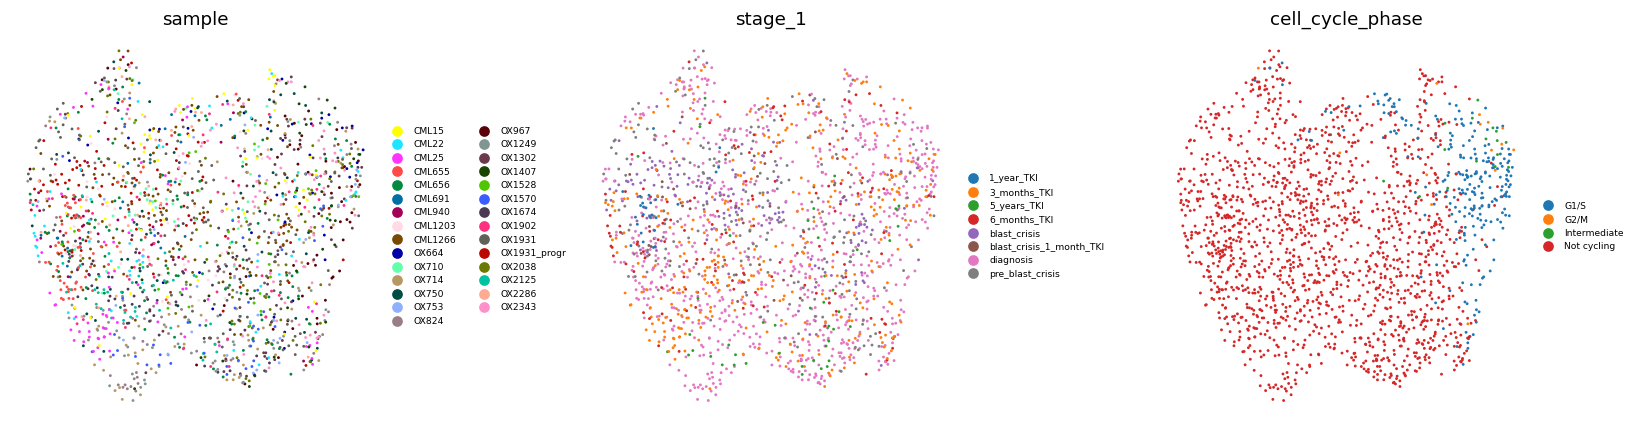

In [9]:
il_post = ilisi(adata.obsm['X_pca_harmony'][:,:NP], adata.obs['sample'].values)
n_samp = adata.obs['sample'].nunique()
print(f'iLISI: post-Harmony(n_pcs={NP}, theta={theta}) = {il_post:.2f} of {ceiling:.2f} ceiling, {n_samp} samples')
print(f'{n_samp} samples share one continuous manifold (one connected component after island removal)')
print('disease stages (diagnosis / TKI timepoints / blast crisis) overlap rather than segregating')
print('Gate 1: samples intermix per-neighbourhood on one continuous manifold -> GO')
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax,col in zip(axes, ['sample','stage_1','cell_cycle_phase']):
    lg = None if col=='sample' else 'right margin'
    sc.pl.umap(plot, color=col, size=14, frameon=False, show=False, ax=ax, legend_fontsize=6, title=col)
fig.tight_layout()

### Save processed data

In [10]:
for c in adata.obs.columns:
    col = adata.obs[c]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        keep_num = col.notna().sum()>0 and conv.notna().sum() >= 0.9*col.notna().sum()
        adata.obs[c] = conv if keep_num else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (1845, 19529)


### Sample-integration figure (deliverable) — house style `(3.5,1.5)` horizontal strip

saved samples.pdf | cells: 1845


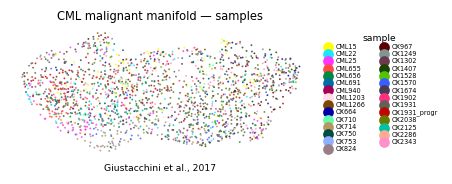

In [11]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=6, alpha=.8, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=2, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.2, fontsize=4.2, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('CML malignant manifold — samples', size=7.5)
ax.text(.5,-.12,'Giustacchini et al., 2017', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])